In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [28]:
df=pd.read_csv("/content/Heart_Disease_Prediction.csv")

In [29]:
le = LabelEncoder()
df["Heart Disease"] = le.fit_transform(df["Heart Disease"])

In [30]:
X = df.drop("Heart Disease", axis=1).values
Y = df["Heart Disease"].values.reshape(-1,1)

In [31]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [32]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

In [33]:
np.random.seed(1)
W1 = np.random.randn(X.shape[1], 10)
b1 = np.random.randn(1, 10)
W2 = np.random.randn(10, 1)
b2 = np.random.randn(1, 1)

learning_rate = 0.1
epochs = 5000
mse_list = []

In [34]:
for epoch in range(epochs):
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    y_pred = sigmoid(z2)

    mse = np.mean((Y - y_pred) ** 2)
    mse_list.append(mse)

    error_output = (Y - y_pred) * sigmoid_derivative(y_pred)
    error_hidden = np.dot(error_output, W2.T) * sigmoid_derivative(a1)

    W2 += learning_rate * np.dot(a1.T, error_output)
    b2 += learning_rate * np.sum(error_output, axis=0, keepdims=True)
    W1 += learning_rate * np.dot(X.T, error_hidden)
    b1 += learning_rate * np.sum(error_hidden, axis=0, keepdims=True)

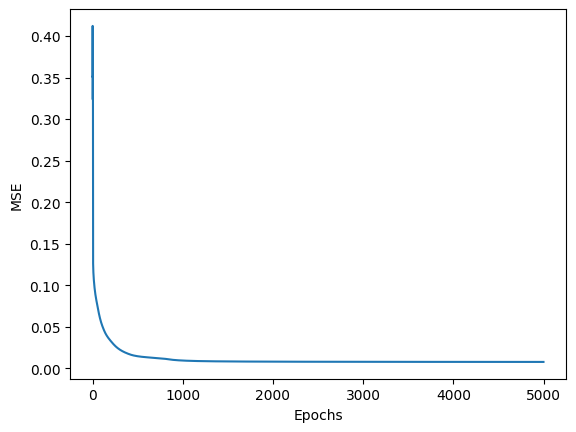

In [35]:
plt.plot(mse_list)
plt.xlabel("Epochs")
plt.ylabel("MSE")
plt.show()

In [36]:
predictions = (y_pred > 0.5).astype(int)
accuracy = np.mean(predictions == Y)
print("Training Accuracy:", round(accuracy * 100, 2), "%")

Training Accuracy: 99.26 %
